In [1]:
import os
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

2026-07-06 12:59:45.494636: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783335585.514792   12414 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783335585.520797   12414 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-06 12:59:45.541587: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from keras.models import Model
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# Load Data

In [3]:
DATASET_PATH = './dataset/'

In [4]:
image_base_path = os.path.join(DATASET_PATH, 'frames')
image_base_path

'./dataset/frames'

In [5]:
mask_base_path = os.path.join(DATASET_PATH, 'lane-masks')
mask_base_path

'./dataset/lane-masks'

In [6]:
all_image_paths = []
all_mask_paths = []

In [7]:
image_filenames = os.listdir(image_base_path)

In [8]:
for file_name in image_filenames:

    if file_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        
        img_path = os.path.join(image_base_path, file_name)
        mask_path = os.path.join(mask_base_path, file_name)
        
        if os.path.exists(mask_path):
            all_image_paths.append(img_path)
            all_mask_paths.append(mask_path)

In [9]:
print({len(all_image_paths)})
print({len(all_mask_paths)})

{4759}
{4759}


In [10]:
all_image_paths[4000]

'./dataset/frames/79.png'

In [11]:
all_mask_paths[4000]

'./dataset/lane-masks/79.png'

In [12]:
train_images, val_images, train_masks, val_masks = train_test_split(
    all_image_paths, all_mask_paths, test_size=0.1, random_state=42)

In [13]:
len(train_images)

4283

In [14]:
len(val_images)

476

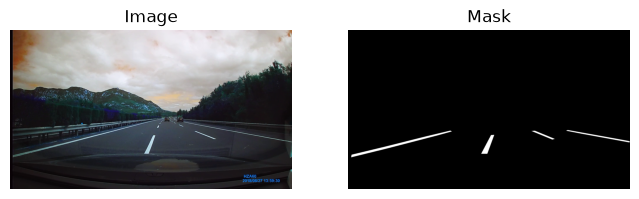

In [16]:
sample_image = train_images[200]
sample_mask = train_masks[200]

image = cv2.imread(sample_image, cv2.COLOR_BGR2RGB)
mask = cv2.imread(sample_mask, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.title("Image")
plt.imshow(image)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Mask")
plt.imshow(mask, cmap='gray') 
plt.axis('off')

plt.show()

# Masks Pixel Check

In [17]:
problematic_masks = []
all_unique_values = set()

for mask_path in all_mask_paths:
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    unique_values = np.unique(mask)
    
    all_unique_values.update(unique_values)
    
    extra_values = set(unique_values) - {0, 255}
    
    if extra_values:
        problematic_masks.append((mask_path, unique_values))

print(f"Global unique pixel values found in all masks: {sorted(list(all_unique_values))}")

Global unique pixel values found in all masks: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(247), np.uint8(248), np.uint8(249), np.uint8(250), np.uint8(251), np.uint8(252), np.uint8(253), np.uint8(254), np.uint8(255)]


# Create Dataset

In [18]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 16

In [19]:
def load_image_and_mask(image_path, mask_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)


    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.where(mask > 127, tf.cast(1, tf.uint8), tf.cast(0, tf.uint8))
    mask = tf.image.resize(mask, IMG_SIZE, method='nearest')

    return img, mask

In [20]:
def augment_photometric(image, mask):
    image = tf.image.random_brightness(image, max_delta=0.05)
    image = tf.image.random_contrast(image, lower=0.95, upper=1.05)
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, mask

In [21]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02),
], name="data_augmentation")

I0000 00:00:1783335704.139976   12414 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7155 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [22]:
def augment_geometric_tf(image, mask):
    mask_float = tf.cast(mask, tf.float32)
    stacked = tf.concat([image, mask_float], axis=-1)
    augmented_stacked = data_augmentation(stacked)
    augmented_image = augmented_stacked[:, :, :3]
    augmented_mask = augmented_stacked[:, :, 3:]
    augmented_mask = tf.round(augmented_mask)
    augmented_mask = tf.cast(augmented_mask, tf.uint8)
    
    return augmented_image, augmented_mask

In [23]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def final_preprocess_for_resnet(image, mask):
    image = preprocess_input(image)
    return image, mask

In [24]:
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_masks))
train_dataset = train_dataset.map(load_image_and_mask, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.map(augment_geometric_tf, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.map(augment_photometric, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.map(final_preprocess_for_resnet, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(buffer_size=1000).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

In [25]:
val_dataset = tf.data.Dataset.from_tensor_slices((val_images, val_masks))
val_dataset = val_dataset.map(load_image_and_mask, num_parallel_calls=tf.data.AUTOTUNE)
val_dataset = val_dataset.map(final_preprocess_for_resnet, num_parallel_calls=tf.data.AUTOTUNE)
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

In [26]:
print(f"Train dataset with geometric augmentation: {train_dataset}")
print(f"Validation dataset: {val_dataset}")

Train dataset with geometric augmentation: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 256, 256, 1), dtype=tf.uint8, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 256, 256, 1), dtype=tf.uint8, name=None))>


# Pixels Check

In [27]:
for images_batch, masks_batch in train_dataset.take(1):
    for i in range(3):
        image = images_batch[i]
        print(f"Shape: {image.shape}")
        print(f"Dtype: {image.dtype}")
        print(f"Min value: {np.min(image):.4f}")
        print(f"Max value: {np.max(image):.4f}")
        print(f"Mean value: {np.mean(image):.4f}")
        print("-" * 25)

2026-07-06 13:02:06.096315: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:5: Filling up shuffle buffer (this may take a while): 841 of 1000
2026-07-06 13:02:07.531788: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


Shape: (256, 256, 3)
Dtype: <dtype: 'float32'>
Min value: -118.7448
Max value: 147.5968
Mean value: -9.9499
-------------------------
Shape: (256, 256, 3)
Dtype: <dtype: 'float32'>
Min value: -115.0347
Max value: 150.6470
Mean value: 1.4777
-------------------------
Shape: (256, 256, 3)
Dtype: <dtype: 'float32'>
Min value: -123.6800
Max value: 151.0610
Mean value: -18.3451
-------------------------


2026-07-06 13:02:07.948266: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


# Imbalance Data

In [28]:
class_counts = {0: 0, 1: 0}
total_pixels = 0

for images_batch, masks_batch in train_dataset:
    for mask in masks_batch:
        mask_np = mask.numpy()
        total_pixels += mask_np.size
        unique, counts = np.unique(mask_np, return_counts=True)
        for u, c in zip(unique, counts):
            if u in class_counts:
                class_counts[u] += c

2026-07-06 13:02:54.230165: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [29]:
total_pixels

280690688

In [30]:
class_counts

{0: np.int64(270884251), 1: np.int64(9806437)}

# Median Frequency Balancing 

In [31]:
class_frequencies = {cls: count / total_pixels for cls, count in class_counts.items() if count > 0}

frequencies = list(class_frequencies.values())
median_frequency = np.median(frequencies)

mfb_weights = {}
for cls, freq in class_frequencies.items():
    mfb_weights[cls] = median_frequency / freq

for cls in class_counts:
    if cls not in mfb_weights:
        mfb_weights[cls] = 0.0

print(mfb_weights)

{0: np.float64(0.5181007883695682), 1: np.float64(14.311553115570925)}


# Modeling

In [32]:
from tensorflow.keras.layers import Conv2D, BatchNormalization, ReLU, Add, Input, UpSampling2D, Concatenate, AveragePooling2D, GlobalAveragePooling2D

In [33]:
def convolution_block(
    block_input,
    num_filters=256,
    kernel_size=3,
    dilation_rate=1,
    padding="same",
    use_bias=True,
):
    x = Conv2D(
        num_filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="same",
        use_bias=use_bias,
    )(block_input)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    return x

In [34]:
def AtrousSpatialPyramidPooling(aspp_input):
    dims = aspp_input.shape
    x = AveragePooling2D(pool_size=(dims[1], dims[2]))(aspp_input)
    out_pool = UpSampling2D(size=(dims[1], dims[2]), interpolation="bilinear")(x)

    out_1 = convolution_block(aspp_input, kernel_size=1, dilation_rate=1)
    out_6 = convolution_block(aspp_input, kernel_size=3, dilation_rate=6)
    out_12 = convolution_block(aspp_input, kernel_size=3, dilation_rate=12)
    out_18 = convolution_block(aspp_input, kernel_size=3, dilation_rate=18)

    x = Concatenate(axis=-1)([out_pool, out_1, out_6, out_12, out_18])
    output = convolution_block(x, kernel_size=1)
    return output

In [35]:
def DeeplabV3_OS16(image_size, num_classes):
  
    model_input = keras.Input(shape=(image_size, image_size, 3))
    
    base_model = keras.applications.ResNet50(weights='imagenet', include_top=False, input_tensor=model_input)
    
    base_model.trainable = False
    
    x = base_model.get_layer("conv4_block6_out").output

    low_level_features = base_model.get_layer("conv2_block3_out").output

    for i in range(1, 4):
        shortcut = x
        
        if i == 1:
            # 1x1 conv
            x = Conv2D(512, (1, 1), strides=(1, 1), padding="same", name=f"custom_conv5_block{i}_1_conv")(x)
            x = BatchNormalization(name=f"custom_conv5_block{i}_1_bn")(x)
            x = ReLU(name=f"custom_conv5_block{i}_1_relu")(x)
            
            # 3x3 atrous conv + dilation_rate=2
            x = Conv2D(512, (3, 3), strides=(1, 1), padding="same", dilation_rate=2, name=f"custom_conv5_block{i}_2_conv")(x)
            x = BatchNormalization(name=f"custom_conv5_block{i}_2_bn")(x)
            x = ReLU(name=f"custom_conv5_block{i}_2_relu")(x)

            # 1x1 conv
            x = Conv2D(2048, (1, 1), strides=(1, 1), padding="same", name=f"custom_conv5_block{i}_3_conv")(x)
            x = BatchNormalization(name=f"custom_conv5_block{i}_3_bn")(x)

            # Projection Shortcut
            shortcut = Conv2D(2048, (1, 1), strides=(1, 1), padding="same", name=f"custom_conv5_block{i}_0_conv")(shortcut)
            shortcut = BatchNormalization(name=f"custom_conv5_block{i}_0_bn")(shortcut)
        
        else:
            # 1x1 conv
            x = Conv2D(512, (1, 1), strides=(1, 1), padding="same", name=f"custom_conv5_block{i}_1_conv")(x)
            x = BatchNormalization(name=f"custom_conv5_block{i}_1_bn")(x)
            x = ReLU(name=f"custom_conv5_block{i}_1_relu")(x)
            
            # 3x3 atrous conv + dilation_rate=2
            x = Conv2D(512, (3, 3), strides=(1, 1), padding="same", dilation_rate=2, name=f"custom_conv5_block{i}_2_conv")(x)
            x = BatchNormalization(name=f"custom_conv5_block{i}_2_bn")(x)
            x = ReLU(name=f"custom_conv5_block{i}_2_relu")(x)

            # 1x1 conv
            x = Conv2D(2048, (1, 1), strides=(1, 1), padding="same", name=f"custom_conv5_block{i}_3_conv")(x)
            x = BatchNormalization(name=f"custom_conv5_block{i}_3_bn")(x)

        x = Add(name=f"custom_conv5_block{i}_add")([x, shortcut])
        x = ReLU(name=f"custom_conv5_block{i}_out")(x)

    encoder_output = x

    x = AtrousSpatialPyramidPooling(encoder_output)

    input_a = UpSampling2D(size=(4,4),interpolation="bilinear")(x)
    
    input_b = convolution_block(low_level_features, num_filters=48, kernel_size=1)
    
    x = Concatenate(axis=-1)([input_a, input_b])
    x = convolution_block(x)
    x = convolution_block(x)
    x = UpSampling2D(size=(4,4), interpolation="bilinear")(x)
    
    model_output = Conv2D(num_classes, kernel_size=(1, 1), padding="same")(x)
    
    return Model(inputs=model_input, outputs=model_output)

In [36]:
model = DeeplabV3_OS16(image_size=IMG_SIZE[0], num_classes=2)

In [37]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_3_c

 Total params: 40,366,450 (153.99 MB)

 Trainable params: 31,751,058 (121.12 MB)

 Non-trainable params: 8,615,392 (32.87 MB)

In [38]:
from tensorflow.keras import losses

In [39]:
def dice_loss(y_true, y_pred, smooth=1e-6):

    y_pred_probs = tf.nn.softmax(y_pred, axis=-1)
    
    y_true_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=2, axis=-1)
    y_true_one_hot = tf.squeeze(y_true_one_hot, axis=-2)
    
    intersection = tf.reduce_sum(y_true_one_hot * y_pred_probs, axis=[1, 2])
    sum_true = tf.reduce_sum(y_true_one_hot, axis=[1, 2])
    sum_pred = tf.reduce_sum(y_pred_probs, axis=[1, 2])
    
    dice_coefficient = (2. * intersection ) / (sum_true + sum_pred + smooth)
    
    mean_dice_coefficient = tf.reduce_mean(dice_coefficient)
    
    return 1. - mean_dice_coefficient

def combined_loss(y_true, y_pred):
    
    scce = losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
    dice = dice_loss(y_true, y_pred)
    
    return scce + dice

In [40]:
sparse_mean_iou = tf.keras.metrics.MeanIoU(num_classes=2, sparse_y_pred = False)

In [41]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=combined_loss,
    metrics=["accuracy", sparse_mean_iou]
)

In [42]:
from tensorflow.keras import callbacks
callbacks = [
    callbacks.ModelCheckpoint('./bestmodel.keras', 
                             monitor="val_loss",  
                             verbose=1,            
                             save_best_only=True),
]

In [43]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    class_weight=mfb_weights, 
    callbacks=callbacks
)

Epoch 1/30


/home/armin/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1783335824.359751   12514 service.cc:148] XLA service 0x78d17c001f70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783335824.360182   12514 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1070, Compute Capability 6.1
2026-07-06 13:03:45.355404: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1783335826.582267   12514 assert_op.cc:38] Ignoring Assert operator compile_loss/combined_loss/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert

267/268 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - accuracy: 0.9188 - loss: 0.5105 - mean_io_u: 0.6023

W0000 00:00:1783336098.639675   12510 assert_op.cc:38] Ignoring Assert operator compile_loss/combined_loss/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
2026-07-06 13:08:20.538968: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[11,64,64,64]{3,2,1,0}, u8[0]{0}) custom-call(f32[11,64,64,64]{3,2,1,0}, f32[64,64,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]}
2026-07-06 13:08:20.864757: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[11,128,32,32]{3,2,1,0}, u8[0]{0}) custom-call(f32[11

268/268 ━━━━━━━━━━━━━━━━━━━━ 0s 961ms/step - accuracy: 0.9189 - loss: 0.5101 - mean_io_u: 0.6025

W0000 00:00:1783336157.748684   12510 assert_op.cc:38] Ignoring Assert operator compile_loss/combined_loss/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
W0000 00:00:1783336166.957699   12512 assert_op.cc:38] Ignoring Assert operator compile_loss/combined_loss/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
2026-07-06 13:09:27.531193: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[12,64,64,64]{3,2,1,0}, u8[0]{0}) custom-call(f32[12,64,64,64]{3,2,1,0}, f32[64,64,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]}
2026-07-06 13:09:27.888801: I external/local


Epoch 1: val_loss improved from None to 0.34457, saving model to ./bestmodel.keras

Epoch 1: finished saving model to ./bestmodel.keras
268/268 ━━━━━━━━━━━━━━━━━━━━ 384s 1s/step - accuracy: 0.9189 - loss: 0.5101 - mean_io_u: 0.6025 - val_accuracy: 0.9592 - val_loss: 0.3446 - val_mean_io_u: 0.6975
Epoch 2/30
268/268 ━━━━━━━━━━━━━━━━━━━━ 0s 775ms/step - accuracy: 0.9567 - loss: 0.3457 - mean_io_u: 0.6952
Epoch 2: val_loss improved from 0.34457 to 0.33077, saving model to ./bestmodel.keras

Epoch 2: finished saving model to ./bestmodel.keras
268/268 ━━━━━━━━━━━━━━━━━━━━ 224s 809ms/step - accuracy: 0.9567 - loss: 0.3457 - mean_io_u: 0.6952 - val_accuracy: 0.9575 - val_loss: 0.3308 - val_mean_io_u: 0.7000
Epoch 3/30
268/268 ━━━━━━━━━━━━━━━━━━━━ 0s 791ms/step - accuracy: 0.9617 - loss: 0.3132 - mean_io_u: 0.7134
Epoch 3: val_loss improved from 0.33077 to 0.26155, saving model to ./bestmodel.keras

Epoch 3: finished saving model to ./bestmodel.keras
268/268 ━━━━━━━━━━━━━━━━━━━━ 230s 825ms/st

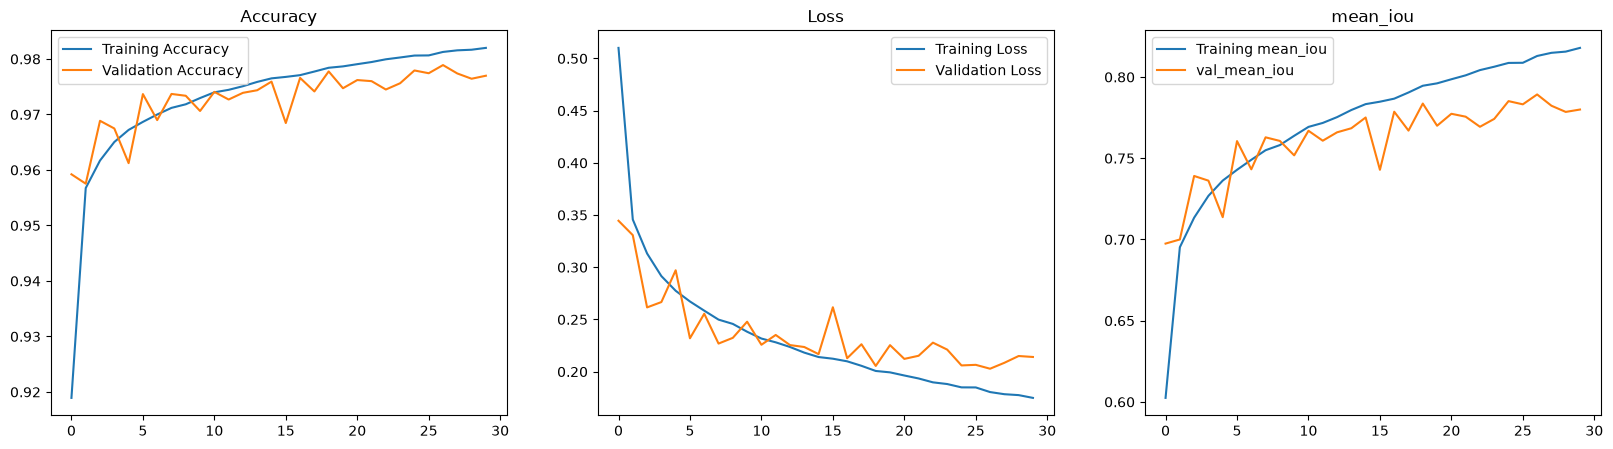

In [44]:
plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history.history['mean_io_u'], label='Training mean_iou')
plt.plot(history.history['val_mean_io_u'], label='val_mean_iou')
plt.title('mean_iou')
plt.legend()

plt.show()

# Evaluation

In [45]:
custom_objects = {
    "combined_loss": combined_loss,
}


best_model = tf.keras.models.load_model(
    './bestmodel.keras',
    custom_objects=custom_objects
)

In [46]:
def predict_and_visualize(model, image_path, mask_path, img_size=(256, 256), confidence_threshold=0.6):
   
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img_resized = tf.image.resize(img, img_size)
    
    img_for_display = img_resized
    
    img_preprocessed = preprocess_input(img_resized)
    img_for_prediction = tf.expand_dims(img_preprocessed, axis=0)

    prediction = model.predict(img_for_prediction)

    max_probs = np.max(prediction, axis=-1)

    predicted_labels = np.argmax(prediction, axis=-1)

    predicted_mask = np.where(max_probs < confidence_threshold, 0, predicted_labels)

    predicted_mask = np.squeeze(predicted_mask)

    _, true_mask_tensor = load_image_and_mask(image_path, mask_path)
    true_mask = np.squeeze(true_mask_tensor.numpy())
    
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(img_for_display / 255.0)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("True Mask")
    plt.imshow(true_mask, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title(f"Predicted Mask (Threshold={confidence_threshold})")
    plt.imshow(predicted_mask, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
    print(f"Unique values in True Mask: {np.unique(true_mask)}")
    print(f"Unique values in Predicted Mask: {np.unique(predicted_mask)}")

2026-07-06 17:51:56.337200: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[1,64,64,64]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,64,64,64]{3,2,1,0}, f32[64,64,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]}
2026-07-06 17:51:56.485409: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[1,128,32,32]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,128,32,32]{3,2,1,0}, f32[128,128,3,3]{3,2,1,0}, f32[128]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward"

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


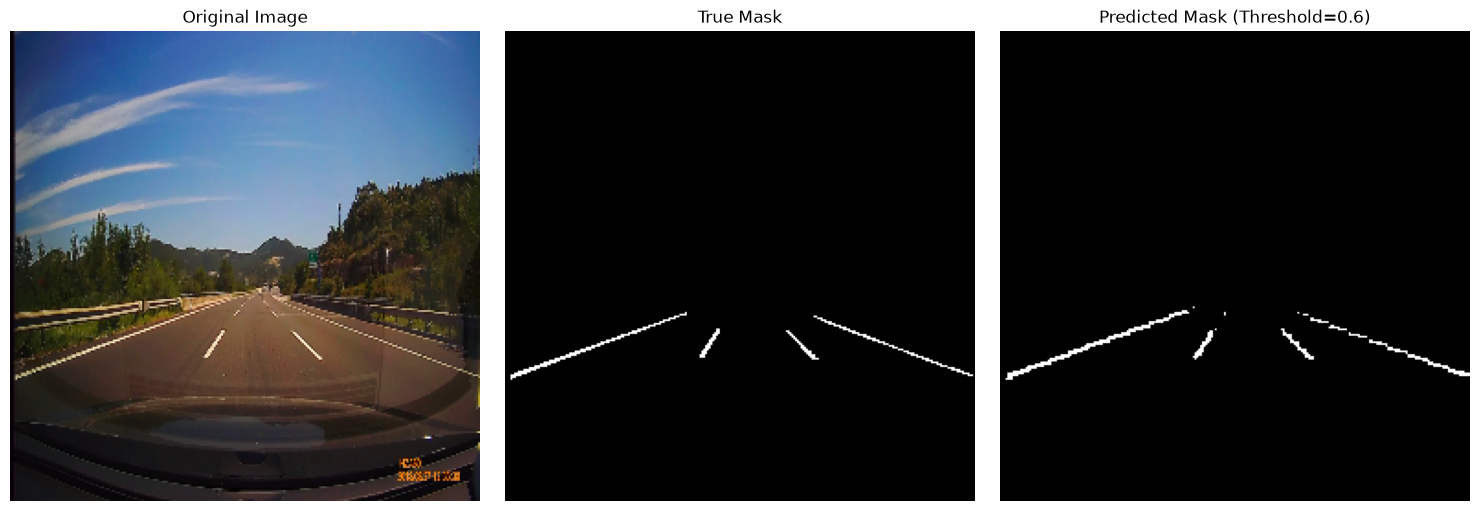

Unique values in True Mask: [0 1]
Unique values in Predicted Mask: [0 1]


In [47]:
sample_index = 100

sample_image_path = val_images[sample_index]
sample_mask_path = val_masks[sample_index]

predict_and_visualize(best_model, sample_image_path, sample_mask_path)